<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    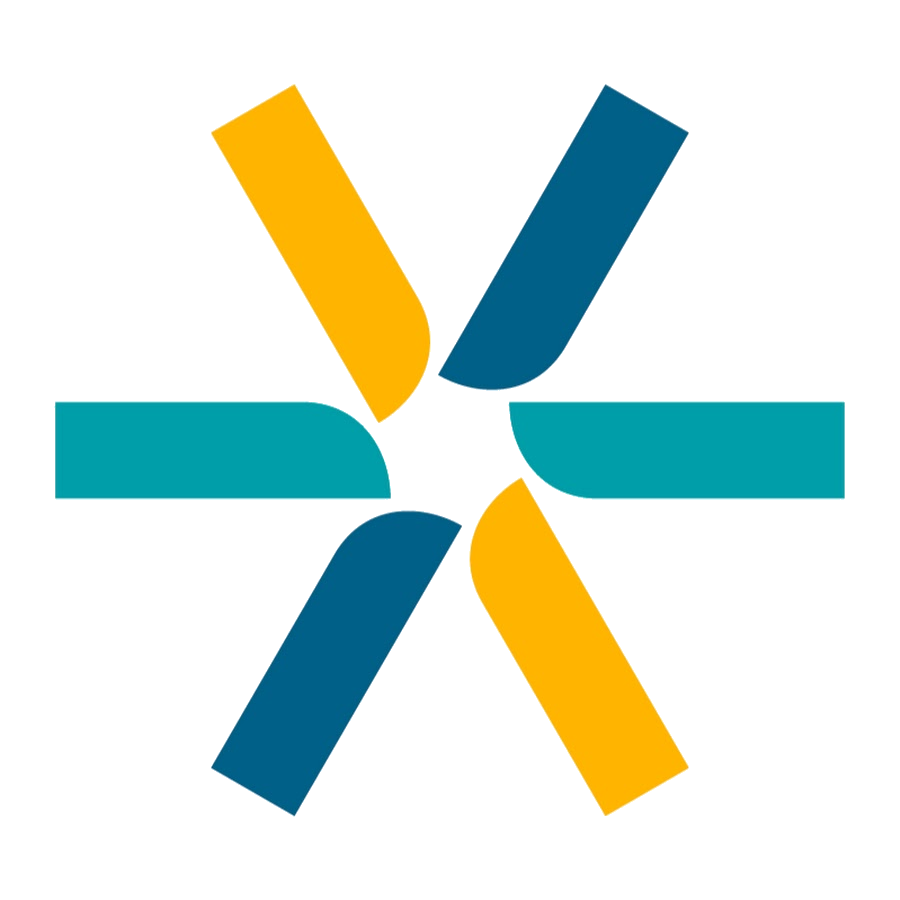
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Agrupamiento por densidad y evaluación · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 8 · Aprendizaje no supervisado</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 43 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La clase 41 agrupó a los agentes por centroides y por jerarquía, y un centroide describe bien una nube, no una luna. Otra idea de grupo: <b>regiones densas</b> de instancias separadas por regiones de baja densidad, de cualquier forma, sin decir cuántas hay, y con lo que queda afuera como <b>ruido</b>. Y la pregunta de fondo de la unidad: sin etiquetas, ¿cómo se sabe si un agrupamiento es bueno?</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Los mismos 868 perfiles de agentes de la clase 41 (seis números por serie, escalados: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Z</code>), con la tarifa aparte. Y los datos <b>construidos</b> del material, rotulados así en cada celda e idénticos a la cátedra: las dos lunas de Géron, tres grupos de distinta densidad, las cinco nubes y las elipses, y los tres casos de la silueta.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">DBSCAN por adentro (vecindad, central, borde, ruido; qué hace eps) y cómo se predice sin predict; OPTICS, HDBSCAN y BIRCH; la afinidad y el desplazamiento de la media; los seis sobre las tres geometrías; y los índices internos (silueta, Davies-Bouldin, Calinski-Harabasz) y el externo (Rand ajustado).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 43: 1 · los datos → A · DBSCAN → B · sin ε fijo → C · sin k → D · evaluar → E · cuál para qué → F · usarlo: los agentes que la densidad deja afuera, y uno nuevo.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Internos: silueta (mayor), Davies-Bouldin (menor), Calinski-Harabasz (mayor). Externo: Rand ajustado (contra la tarifa, o contra otro agrupamiento). Y lo que los grupos significan.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber de estos datos antes de agrupar por densidad</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Sobre los agentes, la densidad dice lo mismo que sobre los socios del gimnasio:</b> en seis columnas escaladas hay <b>una sola región densa</b>. DBSCAN con cualquier eps razonable da un grupo grande más ruido; HDBSCAN con tamaño mínimo 25 no encuentra ningún grupo. Los tres grupos de la clase 41 son particiones de un continuo, no islas.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Lo útil de la densidad acá es el ruido,</b> y además dice algo de la clase 41: la mayor parte del grupo chico de k-medias («muy variables, de verano y en baja») es ruido para DBSCAN. k-medias les armó un grupo a los extremos porque tiene que ubicar a todos; la densidad dice que están sueltos.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">eps es una distancia en el espacio escalado. Las figuras donde la densidad gana (lunas, densidades distintas) son con datos construidos y están rotuladas.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos: los agentes, y las figuras construidas</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los perfiles escalados, y las dos lunas con puntos sueltos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los seis números de cada serie, como en la clase 41. Y las lunas de Géron más 20 puntos sueltos, construidas para que haya ruido que encontrar.</p></div>

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, OPTICS, HDBSCAN, Birch, AffinityPropagation, MeanShift, estimate_bandwidth, cluster_optics_dbscan
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.datasets import make_blobs, make_moons
warnings.filterwarnings("ignore")

AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"
COLORES = [AZUL, ROJO, VERDE, AMBAR, VIOLETA, "#0e7490", "#be185d", "#4d7c0f", "#a16207", "#1e3a8a"]
color_de = lambda etiquetas: ["#9ca3af" if e == -1 else COLORES[e % len(COLORES)] for e in etiquetas]      # gris para el ruido (−1)
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])
def perfil(g):
    """Los seis números de la clase 41."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
escalador = StandardScaler().fit(perfiles[COLUMNAS])
Z = escalador.transform(perfiles[COLUMNAS])
tarifa = demanda.groupby("serie")["categoria_tarifa"].first().loc[perfiles.index]
print(f"{Z.shape[0]} series · {Z.shape[1]} columnas escaladas · la tarifa (no se usa): {tarifa.value_counts().to_dict()}")

X_lu, y_lu = make_moons(n_samples=1000, noise=0.05, random_state=42)                          # el ejemplo de Géron (datos construidos)
rng = np.random.default_rng(2026); sueltos = rng.uniform([-1.5, -1.0], [2.5, 1.5], size=(20, 2))
X_ls = np.vstack([X_lu, sueltos])
print(f"Lunas construidas: {len(X_lu)} puntos en dos lunas + {len(sueltos)} sueltos = {len(X_ls)}")

868 series · 6 columnas escaladas · la tarifa (no se usa): {'Industrial/Comercial Grande': 526, 'Residencial': 267, 'Comercial': 75}
Lunas construidas: 1000 puntos en dos lunas + 20 sueltos = 1020


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · Densidad: DBSCAN</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · Vecindad, central, borde, ruido: a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los cuatro pasos de la diapositiva sobre las lunas construidas, y la comprobación contra <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">DBSCAN</code>, igual que en la cátedra.</p></div>

A mano: 981 centrales · 25 de borde · 14 de ruido · 2 grupos
La biblioteca: 981 centrales · ruido 14 · grupos 2 · mismas centrales: True · misma partición: Rand ajustado 1.00


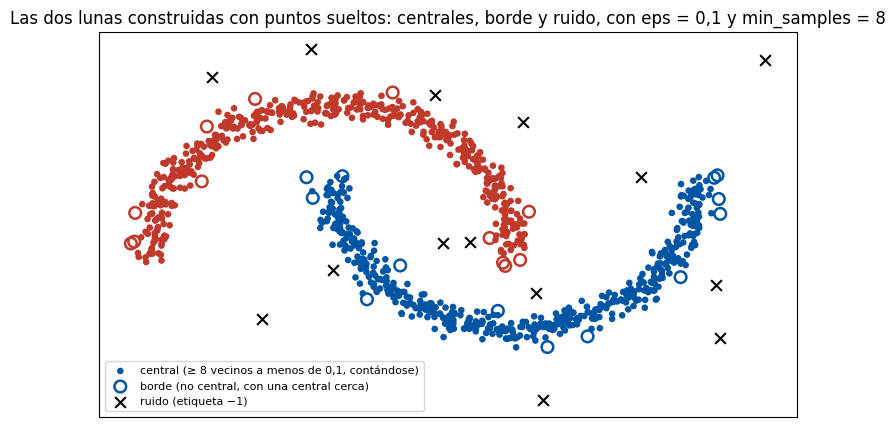

In [3]:
eps, min_samples = 0.1, 8
vecinos = NearestNeighbors(radius=eps).fit(X_ls)
vecindad = vecinos.radius_neighbors(X_ls, return_distance=False)                              # 1. la vecindad-ε de cada punto (se incluye a sí mismo)
cuantos = np.array([len(v) for v in vecindad])
central = cuantos >= min_samples                                                              # 2. central: al menos min_samples en su vecindad
borde = ~central & np.array([central[v].any() for v in vecindad])                             # 3. borde: no central, pero con una central cerca
ruido = ~central & ~borde                                                                     # 4. ruido: ni lo uno ni lo otro

etiquetas_mano = np.full(len(X_ls), -1); grupo = 0                                            # los grupos: cadenas de centrales vecinas
for i in np.where(central)[0]:
    if etiquetas_mano[i] != -1: continue
    pila = [i]; etiquetas_mano[i] = grupo
    while pila:
        j = pila.pop()
        for v in vecindad[j]:
            if etiquetas_mano[v] == -1:
                etiquetas_mano[v] = grupo
                if central[v]: pila.append(v)
    grupo += 1

db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_ls)
print(f"A mano: {central.sum()} centrales · {borde.sum()} de borde · {ruido.sum()} de ruido · {grupo} grupos")
print(f"La biblioteca: {len(db.core_sample_indices_)} centrales · ruido {(db.labels_ == -1).sum()} · grupos {db.labels_.max() + 1} · mismas centrales: {np.array_equal(np.where(central)[0], db.core_sample_indices_)} · misma partición: Rand ajustado {adjusted_rand_score(etiquetas_mano, db.labels_):.2f}")
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_ls[central, 0], X_ls[central, 1], c=color_de(etiquetas_mano[central]), s=14, label="central (≥ 8 vecinos a menos de 0,1, contándose)")
ax.scatter(X_ls[borde, 0], X_ls[borde, 1], s=70, marker="o", facecolors="none", edgecolors=color_de(etiquetas_mano[borde]), linewidths=1.8, label="borde (no central, con una central cerca)")
ax.scatter(X_ls[ruido, 0], X_ls[ruido, 1], c="black", marker="x", s=60, label="ruido (etiqueta −1)")
ax.legend(fontsize=8); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Las dos lunas construidas con puntos sueltos: centrales, borde y ruido, con eps = 0,1 y min_samples = 8")
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Dos radios, y cómo elegir eps</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las lunas limpias con dos eps, y la curva de la distancia al 5.º vecino para las lunas y para los agentes.</p></div>

eps 0.05: 7 grupos · 77 de ruido · Rand ajustado contra las lunas verdaderas 0.31
eps 0.2: 2 grupos · 0 de ruido · Rand ajustado contra las lunas verdaderas 1.00


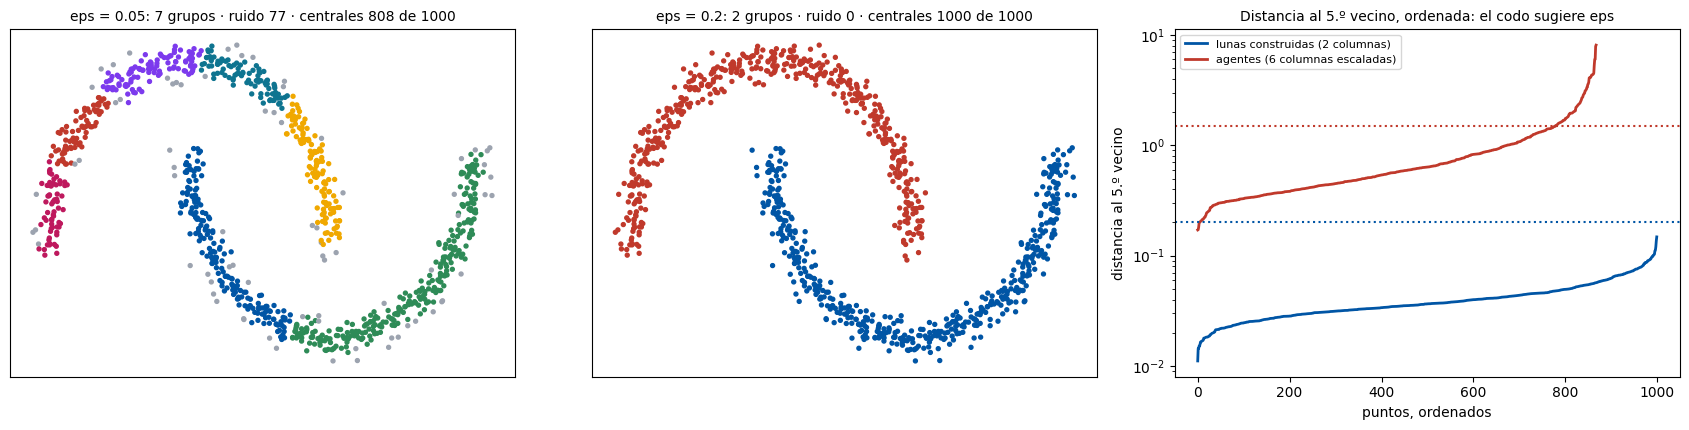

Distancia al 5.º vecino · lunas: mediana 0.037, percentil 95 0.074 · agentes: mediana 0.57, percentil 95 2.21: en seis columnas, y con colas largas, los del borde quedan muy lejos de todo


In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, eps_ in zip(ejes[:2], [0.05, 0.2]):
    d = DBSCAN(eps=eps_, min_samples=5).fit(X_lu)
    ax.scatter(X_lu[:, 0], X_lu[:, 1], c=color_de(d.labels_), s=8); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"eps = {eps_}: {d.labels_.max() + 1} grupos · ruido {(d.labels_ == -1).sum()} · centrales {len(d.core_sample_indices_)} de 1000", fontsize=10)
    print(f"eps {eps_}: {d.labels_.max() + 1} grupos · {(d.labels_ == -1).sum()} de ruido · Rand ajustado contra las lunas verdaderas {adjusted_rand_score(y_lu, d.labels_):.2f}")
def distancia_k(X, k=5):
    d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X); return np.sort(d[:, -1])
ax = ejes[2]
ax.plot(distancia_k(X_lu), color=AZUL, lw=2, label="lunas construidas (2 columnas)"); ax.plot(distancia_k(Z), color=ROJO, lw=2, label="agentes (6 columnas escaladas)")
ax.axhline(0.2, color=AZUL, ls=":"); ax.axhline(1.5, color=ROJO, ls=":")
ax.set_xlabel("puntos, ordenados"); ax.set_ylabel("distancia al 5.º vecino"); ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title("Distancia al 5.º vecino, ordenada: el codo sugiere eps", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Distancia al 5.º vecino · lunas: mediana {np.median(distancia_k(X_lu)):.3f}, percentil 95 {np.percentile(distancia_k(X_lu), 95):.3f} · agentes: mediana {np.median(distancia_k(Z)):.2f}, percentil 95 {np.percentile(distancia_k(Z), 95):.2f}: en seis columnas, y con colas largas, los del borde quedan muy lejos de todo")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · DBSCAN sobre los agentes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Una tabla de eps y min_samples sobre <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Z</code>: cuántos grupos salen y cuánto ruido. Se elige eps = 1,5 y min_samples = 5 (cerca del codo, el percentil 90 de la curva) y se mira quiénes quedan como ruido: en qué columnas son extremos, y de qué grupo de k-medias de la clase 41 vienen.</p></div>

In [5]:
filas = []
for eps_ in [0.8, 1.0, 1.2, 1.5, 2.0]:
    for ms in [5, 10]:
        et = DBSCAN(eps=eps_, min_samples=ms).fit_predict(Z); tam = np.bincount(et[et >= 0]).tolist() if (et >= 0).any() else []
        filas.append({"eps": eps_, "min_samples": ms, "grupos": et.max() + 1, "ruido": int((et == -1).sum()), "% ruido": round(100 * (et == -1).mean(), 1), "tamaños (los mayores)": sorted(tam, reverse=True)[:4]})
display(pd.DataFrame(filas))
EPS = 1.5
db_agentes = DBSCAN(eps=EPS, min_samples=5).fit(Z); es_ruido = db_agentes.labels_ == -1
print(f"eps {EPS} y min_samples 5: {db_agentes.labels_.max() + 1} grupo con {(~es_ruido).sum()} series · {es_ruido.sum()} de ruido · centrales {len(db_agentes.core_sample_indices_)}")
comparacion = pd.DataFrame({"mediana · en el grupo": perfiles.loc[~es_ruido, COLUMNAS].median(), "mediana · ruido": perfiles.loc[es_ruido, COLUMNAS].median(),
                            "ruido: % por debajo del percentil 5": [(perfiles.loc[es_ruido, c_] < perfiles[c_].quantile(0.05)).mean() * 100 for c_ in COLUMNAS],
                            "ruido: % por encima del percentil 95": [(perfiles.loc[es_ruido, c_] > perfiles[c_].quantile(0.95)).mean() * 100 for c_ in COLUMNAS]}).round(3)
print("Quiénes quedan como ruido, comparados con el grupo (en una serie cualquiera, un 5 % está debajo del percentil 5 y un 5 % encima del 95):"); display(comparacion)
km3 = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(Z)                           # el de la clase 41: misma Z, misma semilla
centros3 = pd.DataFrame(escalador.inverse_transform(km3.cluster_centers_), columns=COLUMNAS)
j_grande = int(np.argmax(centros3["log_tamano"].to_numpy())); resto = [j for j in range(3) if j != j_grande]
j_verano = max(resto, key=lambda j: centros3["estacionalidad"].iloc[j]); j_otro = [j for j in resto if j != j_verano][0]
nombres_grupo = {j_grande: "grandes y estables", j_verano: "muy variables, de verano y en baja", j_otro: "chicos, algo más de invierno y en crecimiento"}
print("El ruido, por grupo de k-medias de la clase 41:")
display(pd.crosstab(pd.Series([nombres_grupo[g] for g in km3.labels_], name="grupo de k-medias"), pd.Series(np.where(es_ruido, "ruido", "región densa"), name="DBSCAN")))
print("Ruido por tarifa:", pd.crosstab(es_ruido, tarifa, normalize="columns").loc[True].mul(100).round(1).to_dict(), "% de cada tarifa")

,eps,min_samples,grupos,ruido,% ruido,tamaños (los mayores)
0,0.8,5,1,221,25.5,[647]
1,0.8,10,1,252,29.0,[616]
2,1.0,5,2,156,18.0,"[707, 5]"
3,1.0,10,1,179,20.6,[689]
4,1.2,5,3,105,12.1,"[749, 8, 6]"
5,1.2,10,1,136,15.7,[732]
6,1.5,5,1,56,6.5,[812]
7,1.5,10,1,76,8.8,[792]
8,2.0,5,1,40,4.6,[828]
9,2.0,10,1,42,4.8,[826]


eps 1.5 y min_samples 5: 1 grupo con 812 series · 56 de ruido · centrales 779
Quiénes quedan como ruido, comparados con el grupo (en una serie cualquiera, un 5 % está debajo del percentil 5 y un 5 % encima del 95):


,mediana · en el grupo,mediana · ruido,ruido: % por debajo del percentil 5,ruido: % por encima del percentil 95
log_tamano,3.249,2.736,23.214,0.000
estacionalidad,-0.006,0.198,19.643,21.429
volatilidad,0.084,0.181,3.571,46.429
tendencia_anual,-0.001,-0.067,42.857,26.786
frac_caidas,0.108,0.243,0.000,35.714
cv,0.183,0.804,0.000,73.214


El ruido, por grupo de k-medias de la clase 41:


DBSCAN,región densa,ruido
grupo de k-medias,,
"chicos, algo más de invierno y en crecimiento",262,22
grandes y estables,536,3
"muy variables, de verano y en baja",14,31


Ruido por tarifa: {'Comercial': 0.0, 'Industrial/Comercial Grande': 6.8, 'Residencial': 7.5} % de cada tarifa


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Como con los socios: un grupo grande y ruido, con cualquier eps; abajo de 1,2 aparecen grupitos de cuatro a ocho series y mucho ruido. El ruido son agentes con volatilidad, variabilidad y frecuencia de caídas en el extremo alto. Y de las 45 series del grupo «muy variables, de verano y en baja» de k-medias, la mayoría es ruido: ese grupo no era una región densa sino el conjunto de los que no se parecen a nadie, juntados porque k-medias tiene que ubicar a todos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.4 · Predecir, con vecinos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">DBSCAN no tiene <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code>: k vecinos entrenado con las centrales, con y sin distancia máxima. Las lunas construidas, como en la cátedra.</p></div>

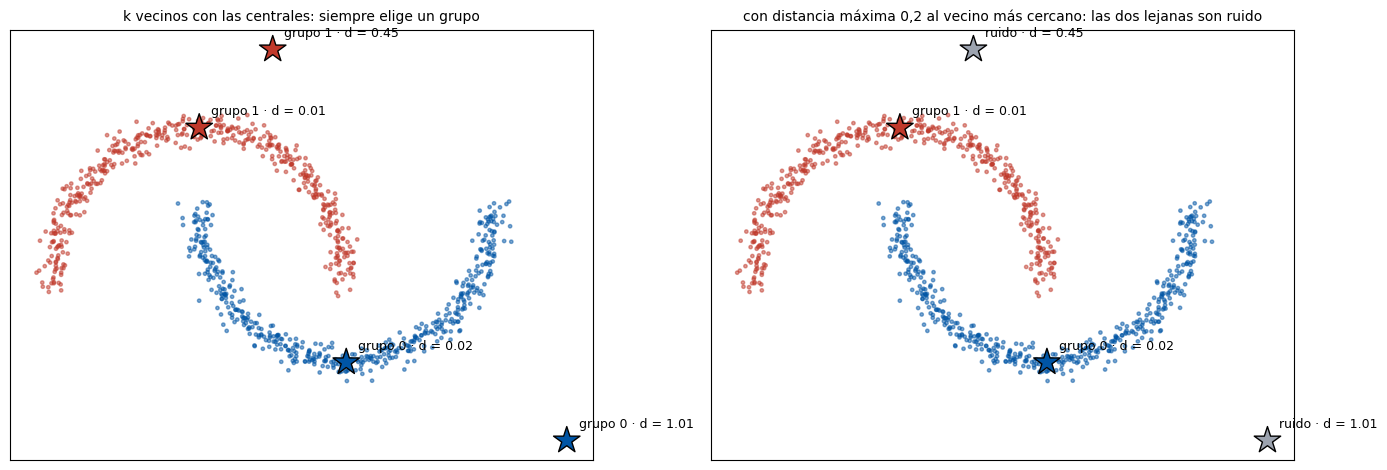

Distancia de cada nueva a la central más cercana: [0.01, 0.02, 0.45, 1.01] · sin máximo: [1, 0, 1, 0] · con máximo 0,2: [1, 0, -1, -1]


In [6]:
db_lu = DBSCAN(eps=0.2, min_samples=5).fit(X_lu)
knn = KNeighborsClassifier(n_neighbors=5).fit(db_lu.components_, db_lu.labels_[db_lu.core_sample_indices_])    # entrenado solo con las centrales
nuevas = np.array([[0.0, 1.0], [1.0, -0.5], [0.5, 1.5], [2.5, -1.0]])                       # dos cerca de una luna, dos lejos
sin_maximo = knn.predict(nuevas)
distancia, _ = knn.kneighbors(nuevas, n_neighbors=1)
con_maximo = np.where(distancia[:, 0] > 0.2, -1, sin_maximo)                                 # más lejos que eps de toda central: ruido
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, etiquetas_nuevas, titulo in [(ejes[0], sin_maximo, "k vecinos con las centrales: siempre elige un grupo"), (ejes[1], con_maximo, "con distancia máxima 0,2 al vecino más cercano: las dos lejanas son ruido")]:
    ax.scatter(X_lu[:, 0], X_lu[:, 1], c=color_de(db_lu.labels_), s=6, alpha=0.5)
    ax.scatter(nuevas[:, 0], nuevas[:, 1], c=color_de(etiquetas_nuevas), marker="*", s=400, edgecolor="black", zorder=5)
    for (x_, y_), e_, d_ in zip(nuevas, etiquetas_nuevas, distancia[:, 0]): ax.text(x_ + 0.08, y_ + 0.08, f"grupo {e_} · d = {d_:.2f}" if e_ >= 0 else f"ruido · d = {d_:.2f}", fontsize=9)
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print(f"Distancia de cada nueva a la central más cercana: {distancia[:, 0].round(2).tolist()} · sin máximo: {sin_maximo.tolist()} · con máximo 0,2: {con_maximo.tolist()}")

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Sin ε fijo: OPTICS, HDBSCAN, BIRCH</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · OPTICS: un rango en lugar de un radio</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Tres grupos de distinta densidad, construidos; el gráfico de alcanzabilidad y los cortes de DBSCAN que salen del mismo ajuste. Igual que en la cátedra.</p></div>

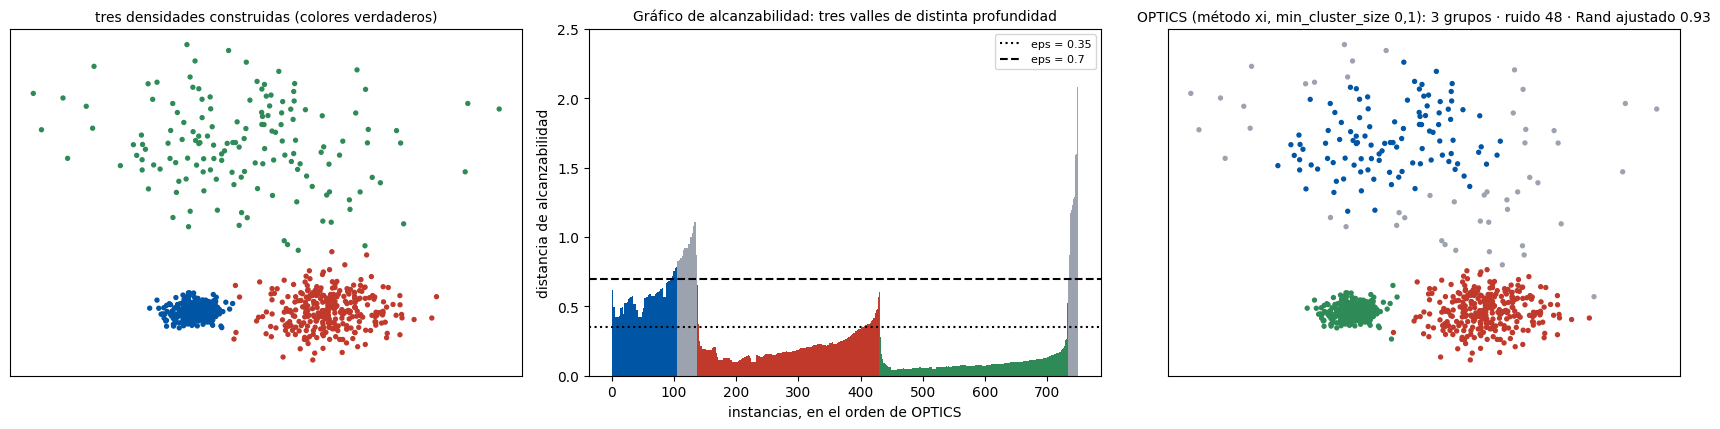

Del mismo ajuste, el corte de DBSCAN con eps 0.35: 2 grupos · ruido 184 · tamaños [265, 301] · Rand ajustado 0.89
Del mismo ajuste, el corte de DBSCAN con eps 0.7: 2 grupos · ruido 56 · tamaños [96, 598] · Rand ajustado 0.38


In [7]:
X_de, y_de = make_blobs(n_samples=[300, 300, 150], centers=[[0, 0], [2.5, 0], [1, 6]], cluster_std=[0.25, 0.6, 1.5], random_state=2026)   # densidades distintas, construidas
optics = OPTICS(min_samples=10, min_cluster_size=0.1).fit(X_de)                                  # min_cluster_size: un grupo tiene al menos el 10 % de los datos
alcanzabilidad = optics.reachability_[optics.ordering_]
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
ejes[0].scatter(X_de[:, 0], X_de[:, 1], c=color_de(y_de), s=8); ejes[0].set_title("tres densidades construidas (colores verdaderos)", fontsize=10); ejes[0].set_xticks([]); ejes[0].set_yticks([])
ejes[1].bar(range(len(X_de)), alcanzabilidad, width=1, color=color_de(optics.labels_[optics.ordering_]))
for e_, est in [(0.35, ":"), (0.7, "--")]: ejes[1].axhline(e_, color="black", ls=est, label=f"eps = {e_}")
ejes[1].set_ylim(0, 2.5); ejes[1].set_xlabel("instancias, en el orden de OPTICS"); ejes[1].set_ylabel("distancia de alcanzabilidad"); ejes[1].legend(fontsize=8)
ejes[1].set_title("Gráfico de alcanzabilidad: tres valles de distinta profundidad", fontsize=10)
et_xi = optics.labels_
ejes[2].scatter(X_de[:, 0], X_de[:, 1], c=color_de(et_xi), s=8); ejes[2].set_xticks([]); ejes[2].set_yticks([])
ejes[2].set_title(f"OPTICS (método xi, min_cluster_size 0,1): {et_xi.max() + 1} grupos · ruido {(et_xi == -1).sum()} · Rand ajustado {adjusted_rand_score(y_de, et_xi):.2f}", fontsize=10)
plt.tight_layout(); plt.show()
for e_ in [0.35, 0.7]:
    et = cluster_optics_dbscan(reachability=optics.reachability_, core_distances=optics.core_distances_, ordering=optics.ordering_, eps=e_)
    print(f"Del mismo ajuste, el corte de DBSCAN con eps {e_}: {et.max() + 1} grupos · ruido {(et == -1).sum()} · tamaños {np.bincount(et[et >= 0]).tolist()} · Rand ajustado {adjusted_rand_score(y_de, et):.2f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · HDBSCAN: todas las escalas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre las tres densidades construidas, y después sobre los agentes con tres tamaños mínimos.</p></div>

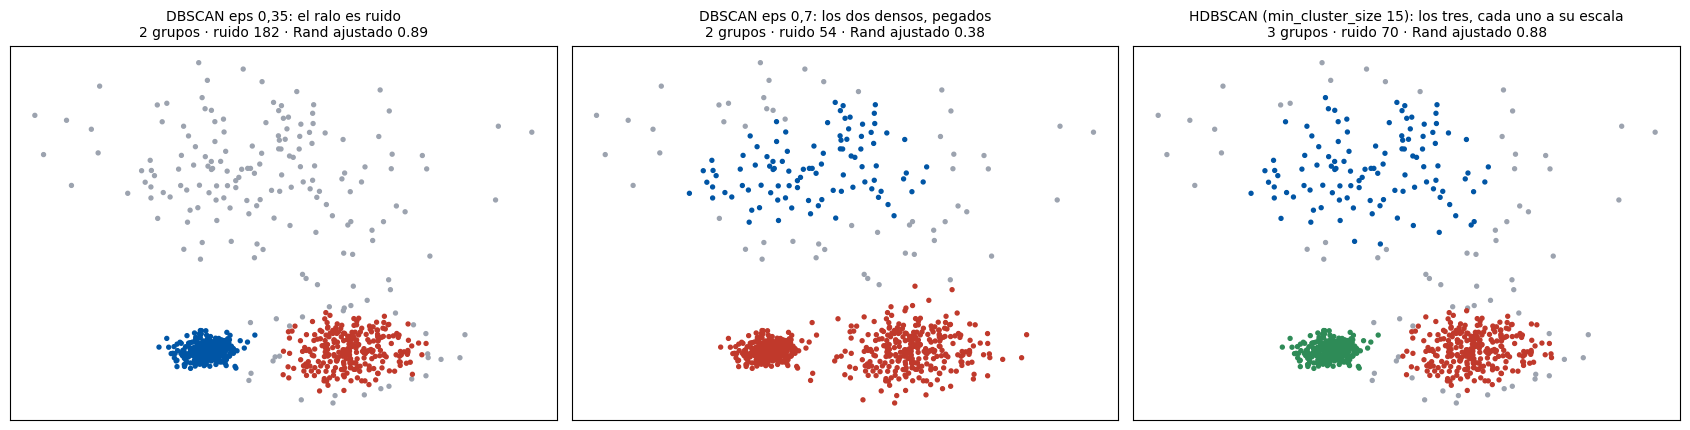

HDBSCAN sobre las tres densidades: tamaños [109, 269, 302] · probabilidad de pertenencia media de los agrupados 0.66
HDBSCAN sobre los agentes, min_cluster_size 25: 0 grupos · ruido 868 de 868 · tamaños []
HDBSCAN sobre los agentes, min_cluster_size 10: 3 grupos · ruido 703 de 868 · tamaños [16, 139, 10]
HDBSCAN sobre los agentes, min_cluster_size 5: 3 grupos · ruido 124 de 868 · tamaños [6, 733, 5]
En seis columnas, los agentes no tienen regiones densas estables separadas por vacío: con tamaño mínimo 25, HDBSCAN lo dice con todo ruido; con 5, un grupo grande y dos grupitos. Los grupos de la clase 41 son cortes de un continuo.


In [8]:
hd = HDBSCAN(min_cluster_size=15).fit(X_de)
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (nombre, et) in zip(ejes, [("DBSCAN eps 0,35: el ralo es ruido", DBSCAN(eps=0.35, min_samples=10).fit_predict(X_de)), ("DBSCAN eps 0,7: los dos densos, pegados", DBSCAN(eps=0.7, min_samples=10).fit_predict(X_de)), ("HDBSCAN (min_cluster_size 15): los tres, cada uno a su escala", hd.labels_)]):
    ax.scatter(X_de[:, 0], X_de[:, 1], c=color_de(et), s=8); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{nombre}\n{et.max() + 1} grupos · ruido {(et == -1).sum()} · Rand ajustado {adjusted_rand_score(y_de, et):.2f}", fontsize=10)
plt.tight_layout(); plt.show()
print(f"HDBSCAN sobre las tres densidades: tamaños {np.bincount(hd.labels_[hd.labels_ >= 0]).tolist()} · probabilidad de pertenencia media de los agrupados {hd.probabilities_[hd.labels_ >= 0].mean():.2f}")
for m in [25, 10, 5]:
    et = HDBSCAN(min_cluster_size=m).fit_predict(Z)
    print(f"HDBSCAN sobre los agentes, min_cluster_size {m}: {et.max() + 1} grupos · ruido {(et == -1).sum()} de {len(Z)} · tamaños {np.bincount(et[et >= 0]).tolist() if (et >= 0).any() else []}")
print("En seis columnas, los agentes no tienen regiones densas estables separadas por vacío: con tamaño mínimo 25, HDBSCAN lo dice con todo ruido; con 5, un grupo grande y dos grupitos. Los grupos de la clase 41 son cortes de un continuo.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · BIRCH: resumir en un árbol</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las cinco nubes construidas con dos umbrales, el reloj contra los minilotes, y los agentes.</p></div>

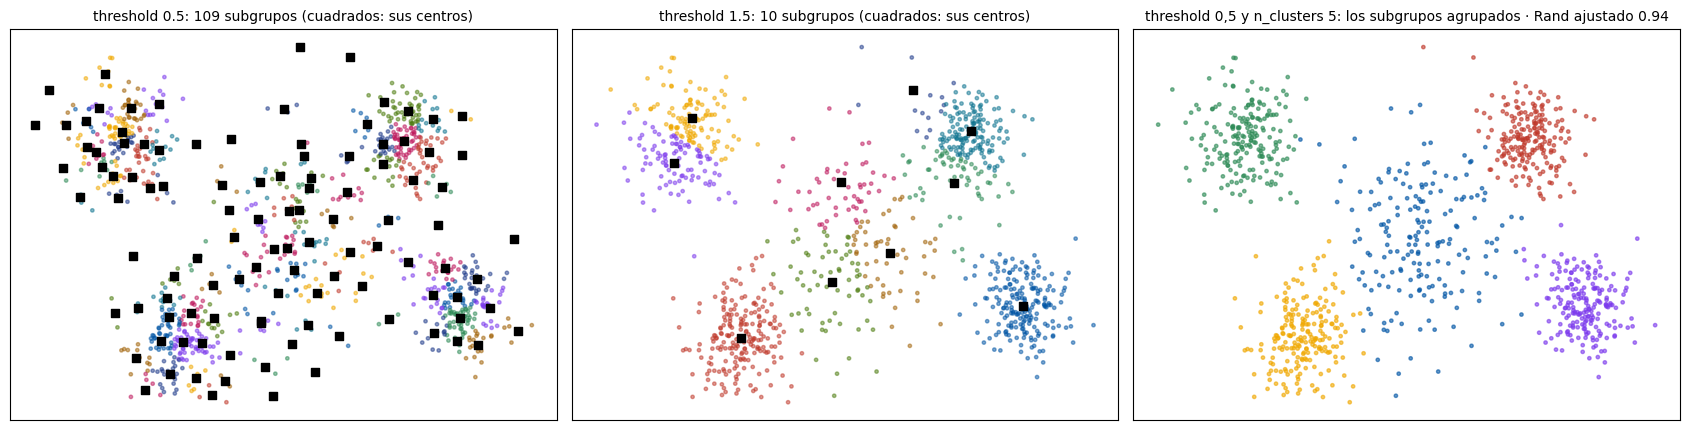

50 000 puntos construidos, 8 grupos · BIRCH (threshold 2,5): 1.89 s, 1744 subgrupos en el árbol · minilotes: 0.06 s · Rand ajustado entre los dos: 1.00
Sobre los agentes, threshold 0,5: 288 subgrupos para 868 series: en seis columnas, pocas cosas caen a menos de 0,5 de otra; el árbol resume poco


In [9]:
X_nubes, y_nubes = make_blobs(n_samples=1000, centers=[[-6, 3], [-4, -3], [0, 0], [4, 3], [6, -2]], cluster_std=[0.9, 0.8, 1.6, 0.7, 0.8], random_state=2026)    # las nubes de la clase 41
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, umbral in zip(ejes[:2], [0.5, 1.5]):
    b_ = Birch(threshold=umbral, n_clusters=None).fit(X_nubes)
    ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=color_de(b_.labels_), s=6, alpha=0.5); ax.scatter(b_.subcluster_centers_[:, 0], b_.subcluster_centers_[:, 1], marker="s", s=30, c="black", zorder=5)
    ax.set_title(f"threshold {umbral}: {len(b_.subcluster_centers_)} subgrupos (cuadrados: sus centros)", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
b5 = Birch(threshold=0.5, n_clusters=5).fit(X_nubes)
ejes[2].scatter(X_nubes[:, 0], X_nubes[:, 1], c=color_de(b5.labels_), s=6, alpha=0.6); ejes[2].set_xticks([]); ejes[2].set_yticks([])
ejes[2].set_title(f"threshold 0,5 y n_clusters 5: los subgrupos agrupados · Rand ajustado {adjusted_rand_score(y_nubes, b5.labels_):.2f}", fontsize=10)
plt.tight_layout(); plt.show()
X_grande, _ = make_blobs(n_samples=50_000, centers=8, n_features=7, cluster_std=1.5, random_state=2026)        # construidos, solo para el reloj
from sklearn.cluster import MiniBatchKMeans
t0 = time.perf_counter(); bg = Birch(threshold=2.5, n_clusters=8).fit(X_grande); t_birch = time.perf_counter() - t0
t0 = time.perf_counter(); mb = MiniBatchKMeans(n_clusters=8, n_init=3, random_state=2026).fit(X_grande); t_mb = time.perf_counter() - t0
print(f"50 000 puntos construidos, 8 grupos · BIRCH (threshold 2,5): {t_birch:.2f} s, {len(bg.subcluster_centers_)} subgrupos en el árbol · minilotes: {t_mb:.2f} s · Rand ajustado entre los dos: {adjusted_rand_score(bg.labels_, mb.labels_):.2f}")
bs = Birch(threshold=0.5, n_clusters=None).fit(Z); print(f"Sobre los agentes, threshold 0,5: {len(bs.subcluster_centers_)} subgrupos para {len(Z)} series: en seis columnas, pocas cosas caen a menos de 0,5 de otra; el árbol resume poco")

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Sin k: afinidad, desplazamiento de la media, y los seis sobre las tres geometrías</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · Propagación de afinidad: ejemplares</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las cinco nubes con tres preferencias, y los agentes.</p></div>

preference None: 17 ejemplares · Rand ajustado contra las nubes verdaderas 0.40 · iteraciones 53
preference -200: 6 ejemplares · Rand ajustado contra las nubes verdaderas 0.86 · iteraciones 50
preference -1000: 5 ejemplares · Rand ajustado contra las nubes verdaderas 0.90 · iteraciones 44


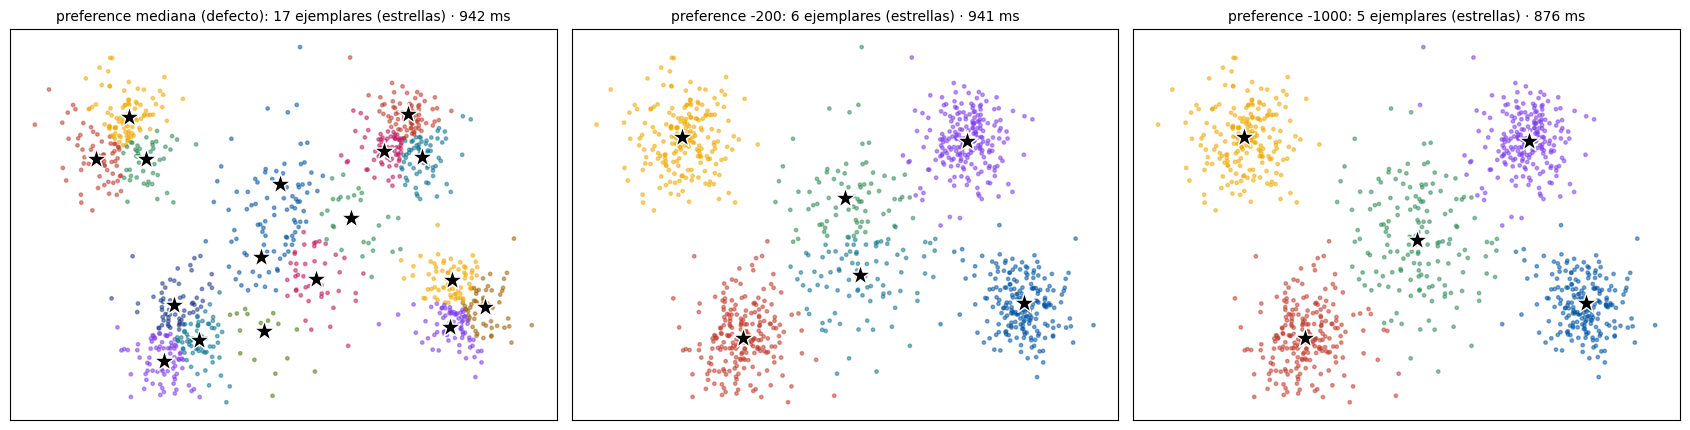

Sobre los agentes, con la preferencia por defecto: 77 ejemplares en 1.4 s · silueta 0.173: demasiados grupos para leer; preference baja para menos


In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, pref in zip(ejes, [None, -200, -1000]):
    t0 = time.perf_counter(); ap = AffinityPropagation(damping=0.9, preference=pref, random_state=2026).fit(X_nubes); t_ap = time.perf_counter() - t0
    ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=color_de(ap.labels_), s=6, alpha=0.5)
    ej = X_nubes[ap.cluster_centers_indices_]; ax.scatter(ej[:, 0], ej[:, 1], marker="*", s=250, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"preference {'mediana (defecto)' if pref is None else pref}: {len(ap.cluster_centers_indices_)} ejemplares (estrellas) · {t_ap * 1000:.0f} ms", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    print(f"preference {pref}: {len(ap.cluster_centers_indices_)} ejemplares · Rand ajustado contra las nubes verdaderas {adjusted_rand_score(y_nubes, ap.labels_):.2f} · iteraciones {ap.n_iter_}")
plt.tight_layout(); plt.show()
t0 = time.perf_counter(); ap_s = AffinityPropagation(damping=0.9, random_state=2026).fit(Z); t_s = time.perf_counter() - t0
print(f"Sobre los agentes, con la preferencia por defecto: {len(ap_s.cluster_centers_indices_)} ejemplares en {t_s:.1f} s · silueta {silhouette_score(Z, ap_s.labels_):.3f}: demasiados grupos para leer; preference baja para menos")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · Desplazamiento de la media: modos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las cinco nubes con tres anchos de banda, y los agentes.</p></div>

quantile 0.1: h 1.56 · 8 modos · Rand ajustado 0.87
quantile 0.2: h 2.90 · 5 modos · Rand ajustado 0.86
quantile 0.3: h 4.92 · 2 modos · Rand ajustado 0.32


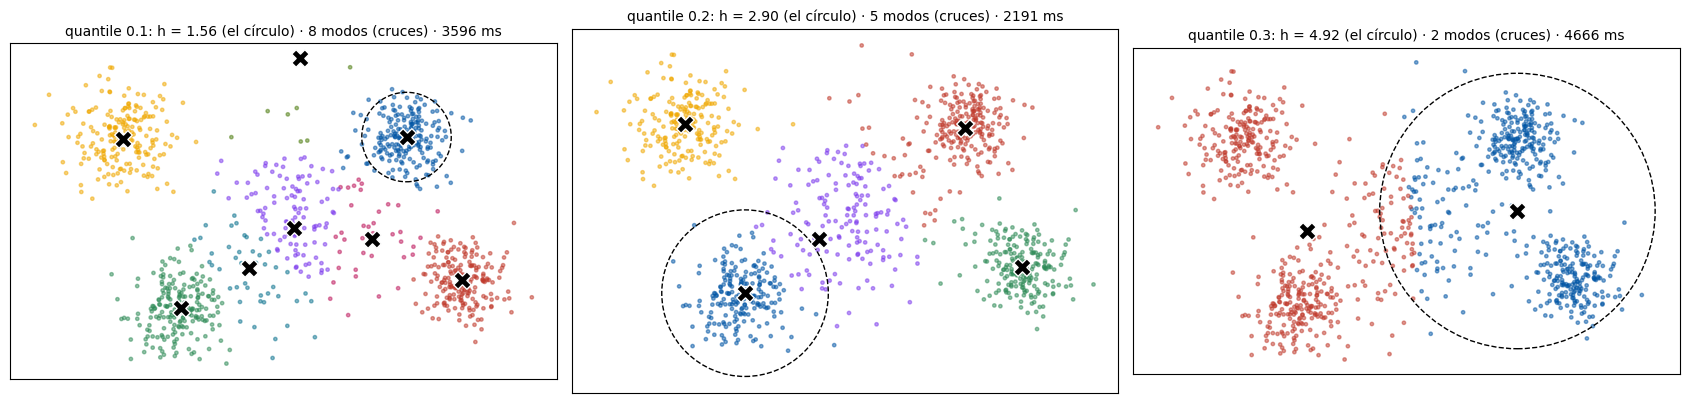

Sobre los agentes, h = 1.95: 42 modos en 3.1 s · el más grande con 718 series; los otros 41 juntan 150 (el mayor de ellos, 27): una sola colina, y los extremos cada uno en su modo. Es lo mismo que dijeron DBSCAN y HDBSCAN.


In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, q in zip(ejes, [0.1, 0.2, 0.3]):
    h = estimate_bandwidth(X_nubes, quantile=q); t0 = time.perf_counter(); ms_ = MeanShift(bandwidth=h).fit(X_nubes); t_ms = time.perf_counter() - t0
    ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=color_de(ms_.labels_), s=6, alpha=0.5)
    ax.scatter(ms_.cluster_centers_[:, 0], ms_.cluster_centers_[:, 1], marker="X", s=160, c="black", edgecolor="white", zorder=5)
    ax.add_patch(plt.Circle(ms_.cluster_centers_[0], h, fill=False, color="black", ls="--")); ax.set_aspect("equal")
    ax.set_title(f"quantile {q}: h = {h:.2f} (el círculo) · {len(ms_.cluster_centers_)} modos (cruces) · {t_ms * 1000:.0f} ms", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    print(f"quantile {q}: h {h:.2f} · {len(ms_.cluster_centers_)} modos · Rand ajustado {adjusted_rand_score(y_nubes, ms_.labels_):.2f}")
plt.tight_layout(); plt.show()
h_s = estimate_bandwidth(Z, quantile=0.2); t0 = time.perf_counter(); ms_s = MeanShift(bandwidth=h_s).fit(Z); t_s = time.perf_counter() - t0
tam_s = np.bincount(ms_s.labels_)
print(f"Sobre los agentes, h = {h_s:.2f}: {len(ms_s.cluster_centers_)} modos en {t_s:.1f} s · el más grande con {tam_s.max()} series; los otros {len(tam_s) - 1} juntan {tam_s.sum() - tam_s.max()} (el mayor de ellos, {np.sort(tam_s)[-2]}): una sola colina, y los extremos cada uno en su modo. Es lo mismo que dijeron DBSCAN y HDBSCAN.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · Los seis sobre las tres geometrías</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La grilla de la diapositiva con las geometrías construidas, igual que en la cátedra.</p></div>

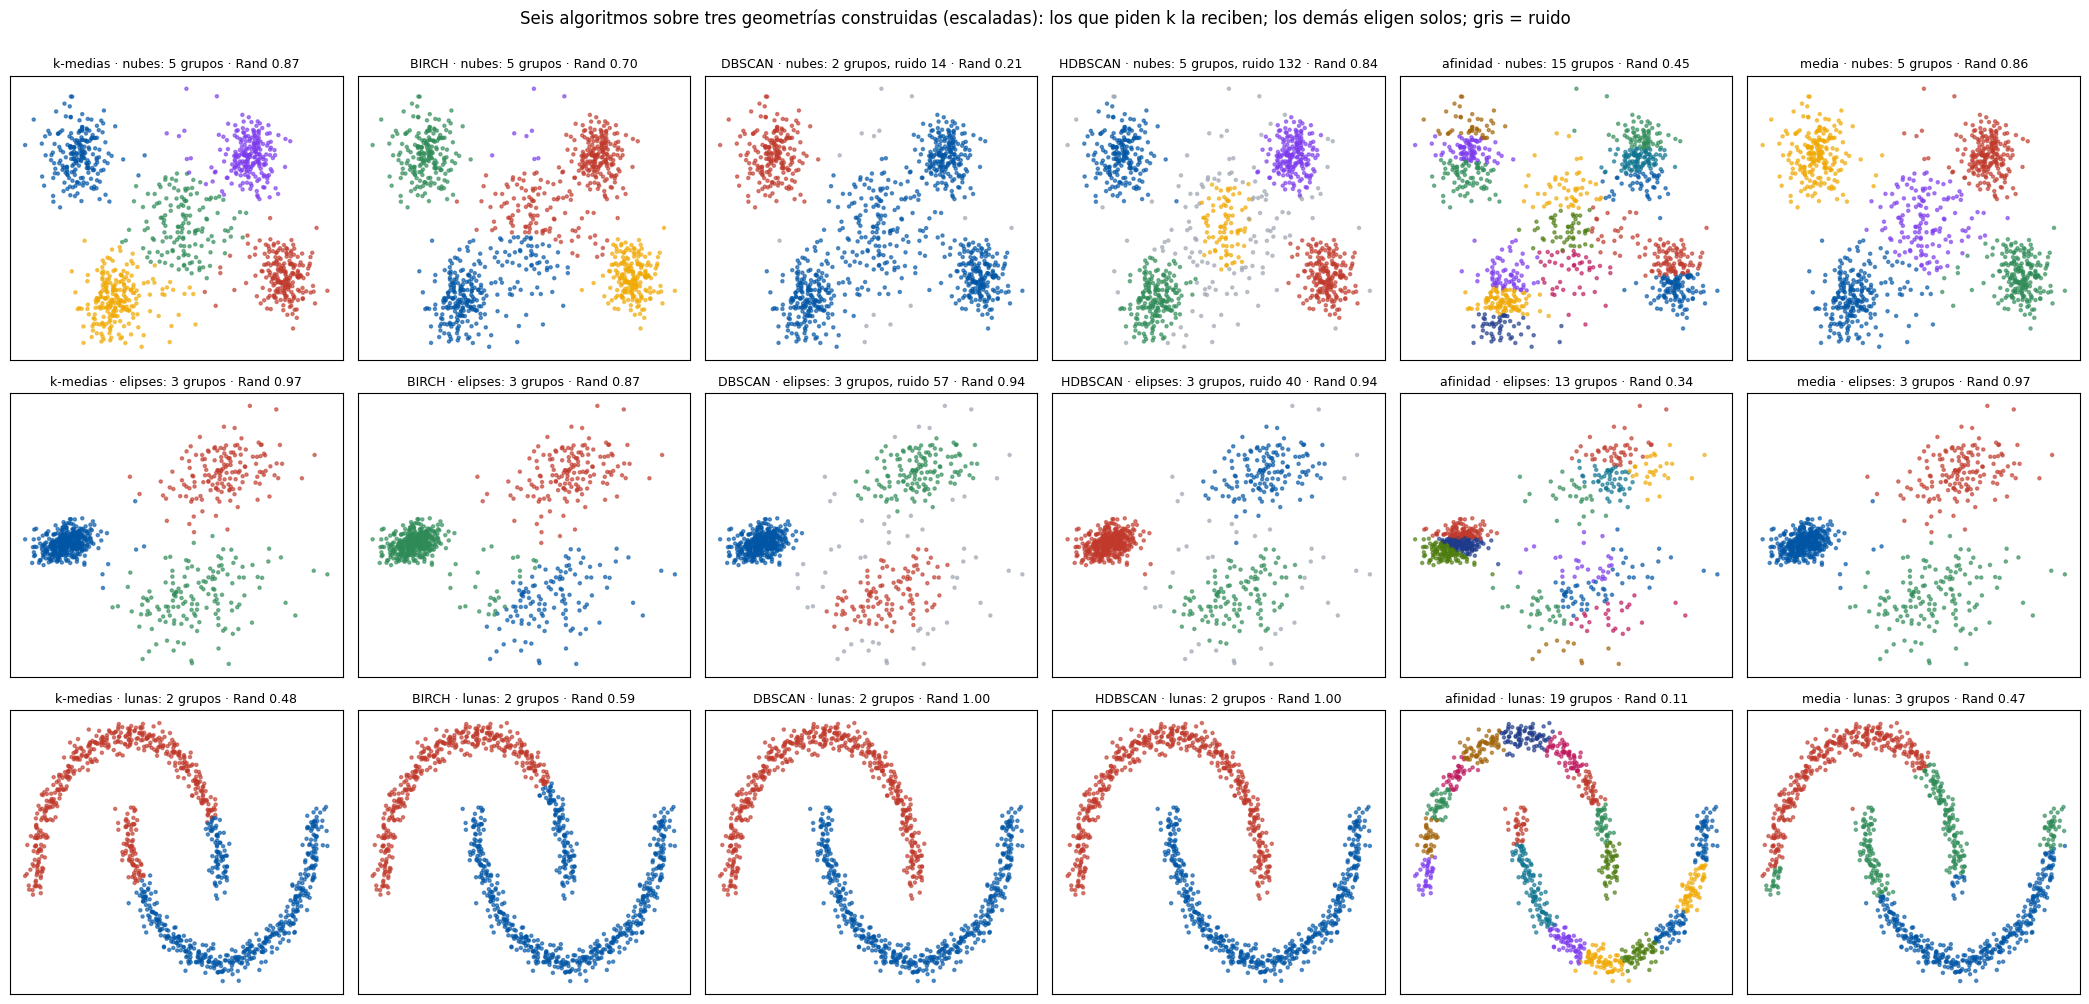

geometría,nubes,elipses,lunas
algoritmo,,,
k-medias,0.87,0.97,0.48
BIRCH,0.70,0.87,0.59
DBSCAN,0.21,0.94,1.00
HDBSCAN,0.84,0.94,1.00
afinidad,0.45,0.34,0.11
media,0.86,0.97,0.47


In [12]:
X_el, y_el = make_blobs(n_samples=[400, 150, 150], centers=[[0, 0], [5, 4], [6, -3]], cluster_std=[0.5, 1.0, 1.5], random_state=2026)
X_el = np.c_[X_el[:, 0] * 2.2 + X_el[:, 1] * 0.6, X_el[:, 1]]
geometrias = [("nubes", StandardScaler().fit_transform(X_nubes), y_nubes, 5), ("elipses", StandardScaler().fit_transform(X_el), y_el, 3), ("lunas", StandardScaler().fit_transform(X_lu), y_lu, 2)]
algoritmos = [("k-medias", lambda X, k: KMeans(n_clusters=k, n_init=10, random_state=2026).fit_predict(X)), ("BIRCH", lambda X, k: Birch(threshold=0.3, n_clusters=k).fit_predict(X)),
              ("DBSCAN", lambda X, k: DBSCAN(eps=0.3, min_samples=10).fit_predict(X)), ("HDBSCAN", lambda X, k: HDBSCAN(min_cluster_size=25).fit_predict(X)),
              ("afinidad", lambda X, k: AffinityPropagation(damping=0.9, random_state=2026).fit_predict(X)), ("media", lambda X, k: MeanShift(bandwidth=estimate_bandwidth(X, quantile=0.2)).fit_predict(X))]
fig, ejes = plt.subplots(3, 6, figsize=(21, 10)); resumen = []
for fila, (nombre_g, Xg, yg, kg) in enumerate(geometrias):
    for col, (nombre_a, hacer) in enumerate(algoritmos):
        et = hacer(Xg, kg); ax = ejes[fila, col]
        ax.scatter(Xg[:, 0], Xg[:, 1], c=color_de(et), s=5, alpha=0.6); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{nombre_a} · {nombre_g}: {et.max() + 1} grupos" + (f", ruido {(et == -1).sum()}" if (et == -1).any() else "") + f" · Rand {adjusted_rand_score(yg, et):.2f}", fontsize=9)
        resumen.append({"geometría": nombre_g, "algoritmo": nombre_a, "grupos": et.max() + 1, "ruido": int((et == -1).sum()), "Rand ajustado": round(adjusted_rand_score(yg, et), 2)})
fig.suptitle("Seis algoritmos sobre tres geometrías construidas (escaladas): los que piden k la reciben; los demás eligen solos; gris = ruido", y=1.0)
plt.tight_layout(); plt.show()
display(pd.DataFrame(resumen).pivot(index="algoritmo", columns="geometría", values="Rand ajustado").loc[[a for a, _ in algoritmos], ["nubes", "elipses", "lunas"]])

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Evaluar: índices internos y externo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.1 · La silueta en tres casos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Bien formados, superpuestos, y con 60 asignados al grupo equivocado: datos construidos, como en la cátedra.</p></div>

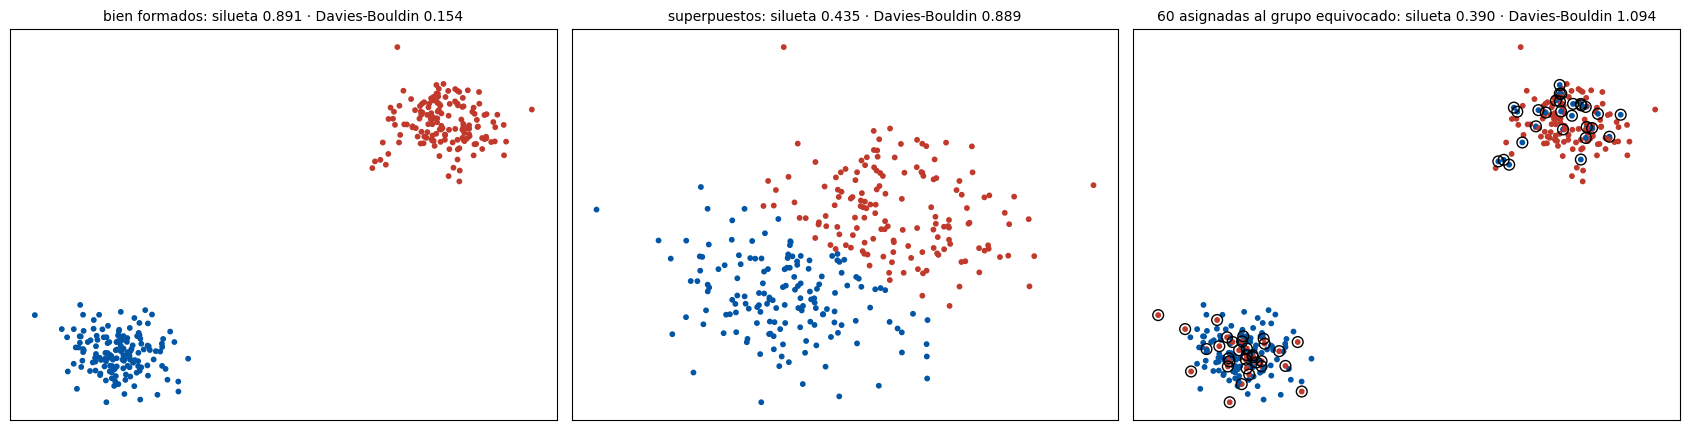

Silueta media de las 60 cambiadas: -0.652 (negativa: b < a) · de las otras 240: 0.651
El promedio del tercer caso (0,39) esconde a las 60 mal asignadas: por eso el diagrama de silueta, no solo el promedio.


In [13]:
X_bien, _ = make_blobs(n_samples=300, centers=[[0, 0], [8, 8]], cluster_std=0.7, random_state=1); et_bien = KMeans(n_clusters=2, n_init=10, random_state=1).fit_predict(X_bien)
X_super, _ = make_blobs(n_samples=300, centers=[[0, 0], [2, 2]], cluster_std=1.2, random_state=1); et_super = KMeans(n_clusters=2, n_init=10, random_state=1).fit_predict(X_super)
cambiadas = np.random.default_rng(1).choice(300, 60, replace=False); et_mal = et_bien.copy(); et_mal[cambiadas] = 1 - et_mal[cambiadas]       # 60 al grupo equivocado, a propósito
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (nombre, Xc, et) in zip(ejes, [("bien formados", X_bien, et_bien), ("superpuestos", X_super, et_super), ("60 asignadas al grupo equivocado", X_bien, et_mal)]):
    ax.scatter(Xc[:, 0], Xc[:, 1], c=color_de(et), s=10); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{nombre}: silueta {silhouette_score(Xc, et):.3f} · Davies-Bouldin {davies_bouldin_score(Xc, et):.3f}", fontsize=10)
ejes[2].scatter(X_bien[cambiadas, 0], X_bien[cambiadas, 1], facecolors="none", edgecolors="black", s=60)
plt.tight_layout(); plt.show()
print(f"Silueta media de las 60 cambiadas: {silhouette_samples(X_bien, et_mal)[cambiadas].mean():.3f} (negativa: b < a) · de las otras 240: {np.delete(silhouette_samples(X_bien, et_mal), cambiadas).mean():.3f}")
print("El promedio del tercer caso (0,39) esconde a las 60 mal asignadas: por eso el diagrama de silueta, no solo el promedio.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.2 · Davies-Bouldin a mano, y los índices contra k</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La fórmula de la diapositiva, y los cuatro índices sobre las cinco nubes construidas.</p></div>

Davies-Bouldin a mano: dispersiones σ [1.12, 1.0, 1.03, 1.15, 1.68] · peor cociente por grupo [0.42, 0.441, 0.565, 0.585, 0.585] · promedio 0.5193 · biblioteca 0.5193


,silueta (mayor),Davies-Bouldin (menor),Calinski-Harabasz (mayor),Rand ajustado contra la verdad (mayor)
k,,,,
2,0.540,0.748,1646.502,0.320
3,0.564,0.622,1695.144,0.499
4,0.605,0.536,2483.000,0.708
5,0.653,0.519,3555.644,0.894
6,0.626,0.672,3316.476,0.870
7,0.597,0.684,3042.729,0.871
8,0.490,0.934,2798.714,0.767


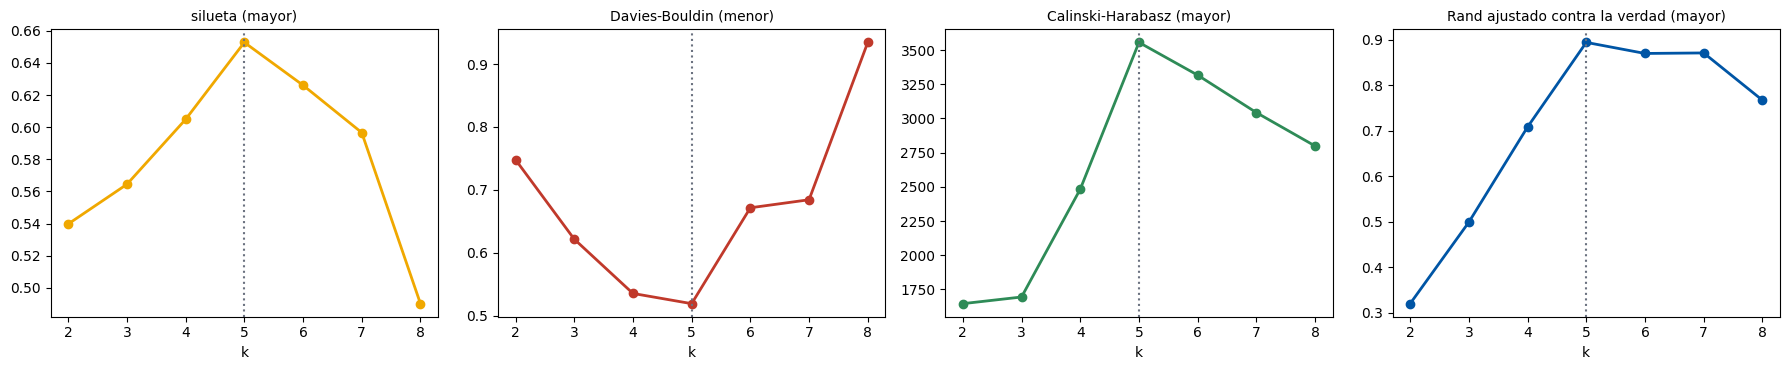

En estas nubes los cuatro coinciden en k = 5. En la figura de la diapositiva, con otras nubes, los internos daban 4 y el externo 5: los internos no siempre coinciden con la verdad, porque miden compacidad, no verdad.


In [14]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=2026).fit(X_nubes); et5 = km5.labels_; centros5 = km5.cluster_centers_
sigma = np.array([np.linalg.norm(X_nubes[et5 == j] - centros5[j], axis=1).mean() for j in range(5)])                    # dispersión de cada grupo
peor = [max((sigma[i] + sigma[j]) / np.linalg.norm(centros5[i] - centros5[j]) for j in range(5) if j != i) for i in range(5)]   # el peor par de cada grupo
print(f"Davies-Bouldin a mano: dispersiones σ {sigma.round(2).tolist()} · peor cociente por grupo {np.round(peor, 3).tolist()} · promedio {np.mean(peor):.4f} · biblioteca {davies_bouldin_score(X_nubes, et5):.4f}")
filas = []
for k in range(2, 9):
    et = KMeans(n_clusters=k, n_init=10, random_state=2026).fit_predict(X_nubes)
    filas.append({"k": k, "silueta (mayor)": silhouette_score(X_nubes, et), "Davies-Bouldin (menor)": davies_bouldin_score(X_nubes, et), "Calinski-Harabasz (mayor)": calinski_harabasz_score(X_nubes, et), "Rand ajustado contra la verdad (mayor)": adjusted_rand_score(y_nubes, et)})
indices = pd.DataFrame(filas).set_index("k"); display(indices.round(3))
fig, ejes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, color in zip(ejes, indices.columns, [AMBAR, ROJO, VERDE, AZUL]):
    ax.plot(indices.index, indices[col], marker="o", color=color, lw=2); ax.set_xlabel("k"); ax.set_title(col, fontsize=10)
    mejor = indices[col].idxmin() if "menor" in col else indices[col].idxmax(); ax.axvline(mejor, color=GRIS, ls=":")
plt.tight_layout(); plt.show()
print("En estas nubes los cuatro coinciden en k = 5. En la figura de la diapositiva, con otras nubes, los internos daban 4 y el externo 5: los internos no siempre coinciden con la verdad, porque miden compacidad, no verdad.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.3 · Los índices sobre los agentes: k-medias contra DBSCAN</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">k-medias con k de 2 a 6 y DBSCAN (eps 1,5) sobre los agentes, con los tres internos y el externo contra la tarifa. Con ruido, la silueta y Davies-Bouldin se calculan sin él.</p></div>

In [15]:
filas = []
for k in range(2, 7):
    et = KMeans(n_clusters=k, n_init=10, random_state=2026).fit_predict(Z)
    filas.append({"agrupamiento": f"k-medias, k = {k}", "grupos": k, "ruido": 0, "silueta": silhouette_score(Z, et), "Davies-Bouldin": davies_bouldin_score(Z, et), "Calinski-Harabasz": calinski_harabasz_score(Z, et), "Rand ajustado contra la tarifa": adjusted_rand_score(tarifa, et)})
et = db_agentes.labels_; con = et >= 0
e_grupo = np.where(et == -1, et.max() + 1, et)
filas.append({"agrupamiento": f"DBSCAN eps {EPS} (ruido como un grupo más)", "grupos": len(np.unique(e_grupo)), "ruido": int((~con).sum()), "silueta": silhouette_score(Z, e_grupo), "Davies-Bouldin": davies_bouldin_score(Z, e_grupo), "Calinski-Harabasz": calinski_harabasz_score(Z, e_grupo), "Rand ajustado contra la tarifa": adjusted_rand_score(tarifa, e_grupo)})
filas.append({"agrupamiento": f"DBSCAN eps {EPS} (sin el ruido)", "grupos": len(np.unique(et[con])), "ruido": int((~con).sum()), "silueta": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan, "Rand ajustado contra la tarifa": adjusted_rand_score(tarifa[con], et[con])})
display(pd.DataFrame(filas).set_index("agrupamiento").round(3))
print("Con un solo grupo (DBSCAN sin el ruido) no hay silueta ni Davies-Bouldin: necesitan al menos dos. Con el ruido como grupo dan un número, pero no es un agrupamiento en dos grupos: es uno más lo que sobra.")
print("Contra la tarifa, todos dan un Rand ajustado cercano a cero: los grupos de comportamiento no son las tarifas. En el gimnasio, k = 3 coincidía algo con el plan (por la cuota); acá no hay ninguna columna que «sea» la tarifa.")

,grupos,ruido,silueta,Davies-Bouldin,Calinski-Harabasz,Rand ajustado contra la tarifa
agrupamiento,,,,,,
"k-medias, k = 2",2,0,0.384,1.515,287.808,0.075
"k-medias, k = 3",3,0,0.301,1.576,230.512,0.071
"k-medias, k = 4",4,0,0.297,1.386,218.919,0.069
"k-medias, k = 5",5,0,0.288,1.337,205.353,0.051
"k-medias, k = 6",6,0,0.277,1.237,208.528,0.042
DBSCAN eps 1.5 (ruido como un grupo más),2,56,0.570,1.734,151.914,-0.013
DBSCAN eps 1.5 (sin el ruido),1,56,NaN,NaN,NaN,0.000


Con un solo grupo (DBSCAN sin el ruido) no hay silueta ni Davies-Bouldin: necesitan al menos dos. Con el ruido como grupo dan un número, pero no es un agrupamiento en dos grupos: es uno más lo que sobra.
Contra la tarifa, todos dan un Rand ajustado cercano a cero: los grupos de comportamiento no son las tarifas. En el gimnasio, k = 3 coincidía algo con el plan (por la cuota); acá no hay ninguna columna que «sea» la tarifa.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · Cuál para qué</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La tabla de la diapositiva, con lo que salió acá</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Nubes esféricas, k dado</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">k-medias (clase 41), en milisegundos. BIRCH con n_clusters da casi lo mismo y escala.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Formas irregulares, ruido</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">DBSCAN: las lunas exactas con eps 0,2, ruido con etiqueta −1. Pide eps y escalar.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Densidades distintas</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">HDBSCAN (u OPTICS con el gráfico de alcanzabilidad): las tres densidades construidas sin eps.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Muchas filas</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">BIRCH o minilotes; BIRCH resume en un árbol y admite partial_fit.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Sin k, pocas filas</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Afinidad (ejemplares) o media (modos): sin k, pero preference y bandwidth son igual de sensibles. Sobre los agentes, la afinidad da decenas de ejemplares y la media una colina grande con muchos modos de una o dos series.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los agentes</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Ninguno de densidad encuentra más de un grupo: no hay vacíos en seis columnas. Para segmentar, k-medias con k = 3 por lo que significa (clase 41), sabiendo que el grupo chico es más «los raros» que un grupo. Para encontrar raros, el ruido de DBSCAN (F, y la clase 46).</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">F · Usarlo: los agentes que la densidad deja afuera, y uno nuevo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los diez agentes más aislados</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ordenados por la distancia a su 5.º vecino, con su perfil traducido (MWh por mes, verano / invierno, variación mensual, crecimiento, caídas), su tarifa y en qué columnas son extremos. Es lo que la clase 46 va a llamar anomalías.</p></div>

In [16]:
d5_agente, _ = NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z); d5_agente = d5_agente[:, -1]
aislados = np.argsort(-d5_agente)[:10]
p_ = perfiles.iloc[aislados]
tabla_a = pd.DataFrame({"distancia al 5.º vecino": d5_agente[aislados].round(2), "tarifa": tarifa.iloc[aislados].values,
                        "MWh/mes": (10 ** p_["log_tamano"]).round(0).values, "verano / invierno": (2 ** p_["estacionalidad"]).round(2).values,
                        "variación mensual (%)": (p_["volatilidad"] * 100).round(1).values, "crecimiento anual (%)": ((10 ** p_["tendencia_anual"] - 1) * 100).round(1).values,
                        "meses con caída fuerte (%)": (p_["frac_caidas"] * 100).round(0).values, "cv": p_["cv"].round(2).values,
                        "DBSCAN": np.where(db_agentes.labels_[aislados] == -1, "ruido", "grupo")}, index=perfiles.index[aislados])
tabla_a.index.name = "serie"; display(tabla_a)
print(f"Los {len(aislados)} más aislados están todos en el ruido de DBSCAN: {(db_agentes.labels_[aislados] == -1).all()} · distancia al 5.º vecino mediana: ruido {np.median(d5_agente[es_ruido]):.2f} contra {np.median(d5_agente[~es_ruido]):.2f} en el grupo")
for i in aislados[:3]:
    extremos = [f"{c_} {perfiles.iloc[i][c_]:.2f} (percentil {100 * (perfiles[c_] < perfiles.iloc[i][c_]).mean():.0f})" for c_ in COLUMNAS
                if (perfiles[c_] < perfiles.iloc[i][c_]).mean() > 0.97 or (perfiles[c_] < perfiles.iloc[i][c_]).mean() < 0.03]
    print(f"{perfiles.index[i]} ({tarifa.iloc[i]}): " + (" · ".join(extremos) if extremos else "extremo en la combinación, no en una columna sola"))

,distancia al 5.º vecino,tarifa,MWh/mes,verano / invierno,variación mensual (%),crecimiento anual (%),meses con caída fuerte (%),cv,DBSCAN
serie,,,,,,,,,
SHELDSCA | GUMAS/AUTOGENERADORES,8.07,Industrial/Comercial Grande,561.0,0.59,98.8,-54.8,44.0,1.87,ruido
YPFTREUZ | GUMAS/AUTOGENERADORES,7.85,Industrial/Comercial Grande,1042.0,1.60,80.0,1370.9,32.0,1.50,ruido
IRTABAAA | GUMAS/AUTOGENERADORES,6.01,Industrial/Comercial Grande,612.0,5.97,74.3,-18.1,39.0,0.89,ruido
YPF-SPRZ | GUMAS/AUTOGENERADORES,5.98,Industrial/Comercial Grande,1274.0,0.96,65.7,483.6,41.0,1.46,ruido
CRANCH3W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,5.31,Industrial/Comercial Grande,42.0,1.40,4.0,-57.7,14.0,1.89,ruido
CMONTE1W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,4.51,Industrial/Comercial Grande,23.0,1.97,8.9,2.9,10.0,1.64,ruido
EMACHIJZ | GUMAS/AUTOGENERADORES,4.40,Industrial/Comercial Grande,2929.0,0.86,27.3,-86.7,52.0,1.34,ruido
CNECNE3W | TARIFA BASE ELECTRODEPENDIENTES,4.38,Residencial,3.0,0.76,62.6,9.3,40.0,0.47,ruido
CNECNE3W | GUMES/GUPAS,4.34,Industrial/Comercial Grande,14.0,0.25,26.8,-39.0,49.0,0.76,ruido


Los 10 más aislados están todos en el ruido de DBSCAN: True · distancia al 5.º vecino mediana: ruido 2.86 contra 0.54 en el grupo
SHELDSCA | GUMAS/AUTOGENERADORES (Industrial/Comercial Grande): estacionalidad -0.77 (percentil 2) · volatilidad 0.99 (percentil 100) · tendencia_anual -0.35 (percentil 2) · frac_caidas 0.44 (percentil 99) · cv 1.87 (percentil 100)
YPFTREUZ | GUMAS/AUTOGENERADORES (Industrial/Comercial Grande): volatilidad 0.80 (percentil 100) · tendencia_anual 1.17 (percentil 100) · cv 1.50 (percentil 100)
IRTABAAA | GUMAS/AUTOGENERADORES (Industrial/Comercial Grande): estacionalidad 2.58 (percentil 100) · volatilidad 0.74 (percentil 100) · frac_caidas 0.39 (percentil 98) · cv 0.89 (percentil 98)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Un agente nuevo: ¿cae en la región densa?</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El procedimiento de A.4 sobre los agentes: la distancia a la central más cercana contra eps, y el grupo de k-medias de la clase 41. Dos agentes inventados: el comercio típico de la clase 41 y uno extremo en todo.</p></div>

In [17]:
nuevos = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25},
                       {"log_tamano": np.log10(300), "estacionalidad": np.log2(3.5), "volatilidad": 0.45, "tendencia_anual": np.log10(0.70), "frac_caidas": 0.40, "cv": 1.2}],
                      index=["comercio típico", "extremo en todo"])[COLUMNAS]
z_nuevos = escalador.transform(nuevos)
centrales = NearestNeighbors(n_neighbors=1).fit(db_agentes.components_)
d_central, _ = centrales.kneighbors(z_nuevos)
for i, nombre in enumerate(nuevos.index):
    g = int(km3.predict(z_nuevos[[i]])[0])
    print(f"{nombre}: distancia a la central más cercana {d_central[i, 0]:.2f} (eps = {EPS}) → {'adentro de la región densa' if d_central[i, 0] <= EPS else 'RUIDO: no se parece a ningún agente'} · "
          f"k-medias lo mandaría al grupo {g} ({nombres_grupo[g]}), a distancia {km3.transform(z_nuevos[[i]])[0, g]:.2f} del centroide")
print("Las dos preguntas son distintas: k-medias siempre contesta «a qué se parece más»; la densidad contesta «si se parece a algo». Para el segundo, la respuesta útil es la segunda.")

comercio típico: distancia a la central más cercana 0.34 (eps = 1.5) → adentro de la región densa · k-medias lo mandaría al grupo 0 (grandes y estables), a distancia 1.72 del centroide
extremo en todo: distancia a la central más cercana 4.37 (eps = 1.5) → RUIDO: no se parece a ningún agente · k-medias lo mandaría al grupo 1 (muy variables, de verano y en baja), a distancia 3.63 del centroide
Las dos preguntas son distintas: k-medias siempre contesta «a qué se parece más»; la densidad contesta «si se parece a algo». Para el segundo, la respuesta útil es la segunda.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>DBSCAN</b> agrupa regiones densas de cualquier forma: central, borde y ruido; a mano y con la biblioteca da lo mismo. eps es una distancia (hay que escalar) y no se deja por defecto; la curva del 5.º vecino sugiere un valor. No tiene predict: k vecinos con las centrales, y una distancia máxima para el ruido.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>OPTICS</b> ordena y mide alcanzabilidad; <b>HDBSCAN</b> recorre todas las escalas; <b>BIRCH</b> resume en un árbol; <b>afinidad</b> y <b>media</b> no piden k y lo cobran en parámetros y tiempo.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Sobre los agentes,</b> todos los de densidad dicen lo mismo: una región densa y ruido. Los grupos de la clase 41 son cortes de un continuo. Lo que la densidad aporta es el ruido: los agentes más volátiles y variables, que en buena parte eran el grupo chico de k-medias.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Evaluar sin etiquetas:</b> silueta, Davies-Bouldin y Calinski-Harabasz miden compacidad y separación, no verdad, y con ruido se calculan sin él. Contra la tarifa, el Rand ajustado da casi cero: los grupos de comportamiento no son las tarifas.</p></div>